# 01 - Data export (Sentinel-1 monthly image + Dynamic World monthly label)

For one small site, this notebook downloads, for each month:
- **radar**: per-pixel median of that month's Sentinel-1 scenes (VV, VH in dB)
- **label**: Dynamic World class with the highest *month-averaged* probability
- **conf**: that highest averaged probability (how sure the label is)
- **n_scenes**: how many radar scenes went into the month

Each month is saved as `data/<site>_<year>-<month>.npz`. A pixel with no valid label is `255` (the ignore value).

Before running: you need an Earth Engine account and a Google Cloud project registered for it.

## 1. Settings (edit these)

In [12]:
SITE_NAME = "kisumu"          # placeholder site, change to your own pick
LAT, LON = -0.0917, 34.7680   # centre of the site
PROJECT = "deep-learning-project-512013"   # your Google Cloud project registered for Earth Engine
YEAR = 2024
MONTHS = range(1, 13)
PASS = "ASCENDING"            # one orbit direction only, so scenes are comparable (this site only has ascending)
SIZE_PX = 1000                # 1000 px x 10 m = 10 km square
SCALE = 10                    # metres per pixel (Sentinel-1 and Dynamic World are both 10 m)

## 2. Connect to Earth Engine

In [6]:
import os
import ee
import numpy as np
import matplotlib.pyplot as plt

try:
    ee.Initialize(project=PROJECT)
except Exception:
    # ask only for the Earth Engine permission, matching the single box ticked on the consent page
    ee.Authenticate(scopes=["https://www.googleapis.com/auth/earthengine"])
    ee.Initialize(project=PROJECT)


Successfully saved authorization token.


## 3. Helper functions

- `month_range` gives the start and end dates of one month.
- `radar_month` builds the month's median radar image and counts the scenes.
- `label_month` averages Dynamic World's class probabilities over the month and picks the top class.
- `download` pulls an Earth Engine image into a NumPy array for our square site.

In [14]:
import io

CLASSES = ["water", "trees", "grass", "flooded_vegetation", "crops",
           "shrub_and_scrub", "built", "bare", "snow_and_ice"]   # index in this list = label value
NODATA_LABEL = 255
NODATA_RADAR = -999.0


def month_range(year, month):
    """Start (inclusive) and end (exclusive) dates of one month."""
    start = ee.Date.fromYMD(year, month, 1)
    return start, start.advance(1, "month")


def radar_month(region, start, end):
    """Median of all Sentinel-1 scenes in the month, per pixel, for VV and VH (dB).
    Also returns how many scenes were used. Scenes with missing data are skipped by the median."""
    s1 = (ee.ImageCollection("COPERNICUS/S1_GRD")
          .filterBounds(region).filterDate(start, end)
          .filter(ee.Filter.eq("instrumentMode", "IW"))
          .filter(ee.Filter.eq("orbitProperties_pass", PASS))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))
    img = s1.select(["VV", "VH"]).median().unmask(NODATA_RADAR)
    return img, s1.size().getInfo()


def label_month(region, start, end):
    """Average each class's Dynamic World probability over the month, then take the best class.
    label = index of the best class, conf = its averaged probability.
    Pixels with no valid observation all month get label 255 and conf 0."""
    dw = (ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
          .filterBounds(region).filterDate(start, end).select(CLASSES))
    probs = dw.mean()                                 # 9 bands: month-average probability per class
    label = probs.toArray().arrayArgmax().arrayGet(0).rename("label").unmask(NODATA_LABEL)
    conf = probs.reduce(ee.Reducer.max()).rename("conf").unmask(0)
    return label.addBands(conf)


def make_grid():
    """Pixel grid: SIZE_PX x SIZE_PX squares of SCALE metres, centred on the site, in the local UTM projection.
    Using metres (UTM) keeps pixels square."""
    zone = int((LON + 180) // 6) + 1
    epsg = f"EPSG:{(32600 if LAT >= 0 else 32700) + zone}"
    x, y = ee.Geometry.Point([LON, LAT]).transform(epsg, 1).coordinates().getInfo()
    half = SIZE_PX * SCALE / 2
    grid = {"dimensions": {"width": SIZE_PX, "height": SIZE_PX},
            "affineTransform": {"scaleX": SCALE, "shearX": 0, "translateX": x - half,
                                "shearY": 0, "scaleY": -SCALE, "translateY": y + half},
            "crsCode": epsg}
    region = ee.Geometry.Rectangle([x - half, y - half, x + half, y + half], epsg, False)
    return grid, region


def download(image, grid):
    """Pull an Earth Engine image into an array shaped (bands, height, width).
    Earth Engine sends raw NPY bytes, so np.load decodes them into a table with one named field per band."""
    raw = ee.data.computePixels({"expression": image, "fileFormat": "NPY", "grid": grid})
    arr = np.load(io.BytesIO(raw))
    return np.stack([arr[name] for name in arr.dtype.names])

In [11]:
grid, region = make_grid()
s1 = ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(region).filterDate("2024-01-01", "2025-01-01")
print("all scenes in 2024:", s1.size().getInfo())
print("by pass direction:", s1.aggregate_histogram("orbitProperties_pass").getInfo())
print("by mode:", s1.aggregate_histogram("instrumentMode").getInfo())
print("polarisations of one scene:", s1.first().get("transmitterReceiverPolarisation").getInfo())


all scenes in 2024: 31
by pass direction: {'ASCENDING': 31}
by mode: {'IW': 31}
polarisations of one scene: ['VV', 'VH']


## 4. Download every month

In [15]:
os.makedirs("data", exist_ok=True)
grid, region = make_grid()

for m in MONTHS:
    start, end = month_range(YEAR, m)
    radar_img, n_scenes = radar_month(region, start, end)
    if n_scenes == 0:
        print(f"{YEAR}-{m:02d}: no radar scenes, skipped")
        continue
    radar = download(radar_img, grid).astype("float32")      # (2, H, W)
    lab = download(label_month(region, start, end), grid)    # (2, H, W): label, conf
    np.savez_compressed(f"data/{SITE_NAME}_{YEAR}-{m:02d}.npz",
                        radar=radar, label=lab[0].astype("uint8"),
                        conf=lab[1].astype("float32"), n_scenes=n_scenes)
    print(f"{YEAR}-{m:02d}: {n_scenes} scenes saved")

2024-01: 3 scenes saved
2024-02: 2 scenes saved
2024-03: 3 scenes saved
2024-04: 2 scenes saved
2024-05: 3 scenes saved
2024-06: 2 scenes saved
2024-07: 3 scenes saved
2024-08: 2 scenes saved
2024-09: 3 scenes saved
2024-10: 2 scenes saved
2024-11: 3 scenes saved
2024-12: 3 scenes saved


## 5. Sanity check (fails loudly if something is off)

In [16]:
import glob
for f in sorted(glob.glob(f"data/{SITE_NAME}_{YEAR}-*.npz")):
    d = np.load(f)
    assert d["radar"].shape == (2, SIZE_PX, SIZE_PX), f
    assert d["label"].shape == (SIZE_PX, SIZE_PX), f
    assert set(np.unique(d["label"])) <= set(range(len(CLASSES))) | {NODATA_LABEL}, f
    print(f, "ok; share of pixels with no label:", round(float((d["label"] == NODATA_LABEL).mean()), 3))

data\kisumu_2024-01.npz ok; share of pixels with no label: 0.009
data\kisumu_2024-02.npz ok; share of pixels with no label: 0.0
data\kisumu_2024-03.npz ok; share of pixels with no label: 0.0
data\kisumu_2024-04.npz ok; share of pixels with no label: 0.0
data\kisumu_2024-05.npz ok; share of pixels with no label: 0.0
data\kisumu_2024-06.npz ok; share of pixels with no label: 0.0
data\kisumu_2024-07.npz ok; share of pixels with no label: 0.0
data\kisumu_2024-08.npz ok; share of pixels with no label: 0.0
data\kisumu_2024-09.npz ok; share of pixels with no label: 0.0
data\kisumu_2024-10.npz ok; share of pixels with no label: 0.0
data\kisumu_2024-11.npz ok; share of pixels with no label: 0.041
data\kisumu_2024-12.npz ok; share of pixels with no label: 0.0


## 6. Look at one month

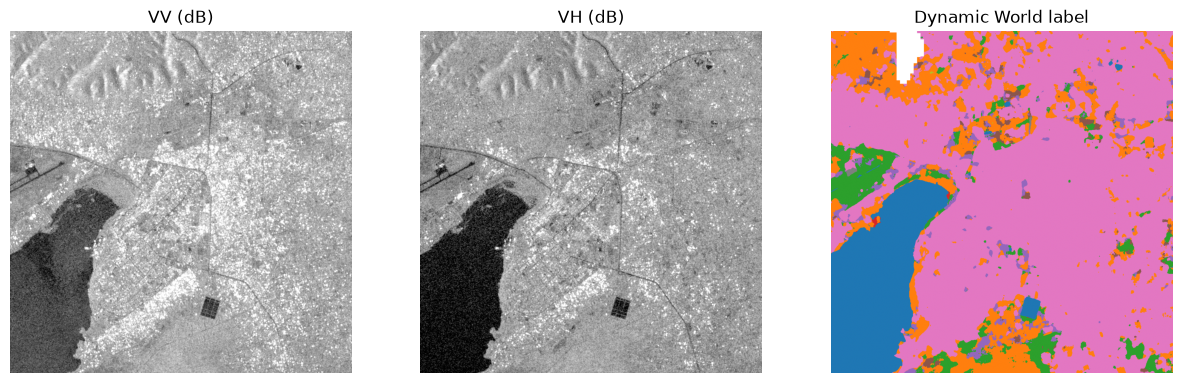

classes: {0: 'water', 1: 'trees', 2: 'grass', 3: 'flooded_vegetation', 4: 'crops', 5: 'shrub_and_scrub', 6: 'built', 7: 'bare', 8: 'snow_and_ice'}


In [17]:
f = sorted(glob.glob(f"data/{SITE_NAME}_{YEAR}-*.npz"))[0]
d = np.load(f)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(d["radar"][0], cmap="gray", vmin=-25, vmax=0); ax[0].set_title("VV (dB)")
ax[1].imshow(d["radar"][1], cmap="gray", vmin=-30, vmax=-5); ax[1].set_title("VH (dB)")
im = ax[2].imshow(np.where(d["label"] == NODATA_LABEL, np.nan, d["label"]), cmap="tab10", vmin=0, vmax=9)
ax[2].set_title("Dynamic World label")
for a in ax: a.axis("off")
plt.show()
print("classes:", dict(enumerate(CLASSES)))